# 3. Разведочный анализ Oxford Flowers 102

Источник — [University of Oxford](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/). 102 класса, фото разных размеров. Нужны `numpy`, `matplotlib`, `pillow`, **`scipy`** для `.mat`-меток. 

## 3.1. Источник, библиотеки и пути

In [1]:
from pathlib import Path
from IPython.display import display
import io
import tarfile
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.io import loadmat

root = Path.cwd()
if not (root / 'data').exists(): root = root.parent
folder = root / 'data' / 'flowers102'
for name in ('102flowers.tgz', 'imagelabels.mat', 'setid.mat'):
    path = folder / name
    assert path.exists(), f'Отсутствует {path}'
    print(name, path.stat().st_size, 'байт')

102flowers.tgz 344862509 байт
imagelabels.mat 502 байт
setid.mat 14989 байт


## 3.2. Метки классов и официальное разбиение
Здесь индексы в `.mat` начинаются с 1; в Python для массивов метки переводим в 0–101, ID файлов оставляем 1–8189.

In [2]:
labels = loadmat(folder / 'imagelabels.mat')['labels'].ravel().astype(int) - 1
split_data = loadmat(folder / 'setid.mat')
split_ids = {
    'train': split_data['trnid'].ravel().astype(int),
    'val': split_data['valid'].ravel().astype(int),
    'test': split_data['tstid'].ravel().astype(int),
}
all_ids = np.concatenate(list(split_ids.values()))
assert len(labels) == 8189 and set(labels) == set(range(102))
assert set(all_ids) == set(range(1, 8190)) and len(np.unique(all_ids)) == len(all_ids)
print('Классов:', len(np.unique(labels)))
print('Размеры:', {name: len(ids) for name, ids in split_ids.items()})

Классов: 102
Размеры: {'train': 1020, 'val': 1020, 'test': 6149}


In [3]:
counts = {name: np.bincount(labels[ids - 1], minlength=102).tolist()
          for name, ids in split_ids.items()}
for name, values in counts.items():
    print(name, 'min/median/max на класс:', min(values), np.median(values), max(values))

train min/median/max на класс: 10 10.0 10
val min/median/max на класс: 10 10.0 10
test min/median/max на класс: 20 46.0 238


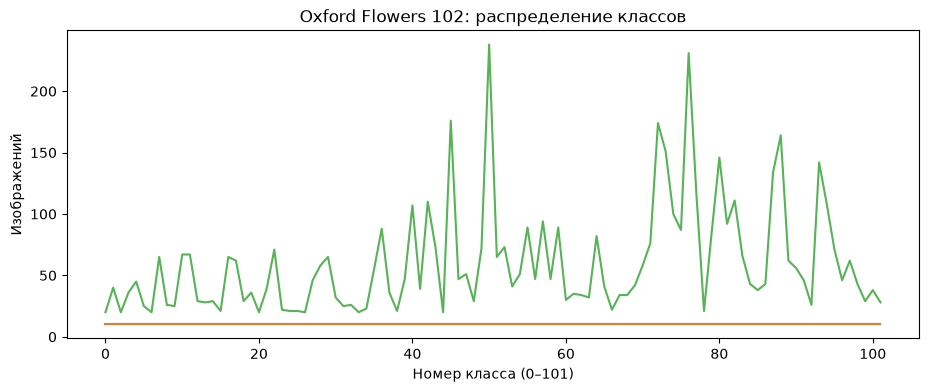

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
for split, values in counts.items():
    ax.plot(np.arange(102), values, label=split, alpha=.8)
ax.set(xlabel='Номер класса (0–101)', ylabel='Изображений', title='Oxford Flowers 102: распределение классов')
display(fig)
plt.close(fig)

## 3.3. Читаем JPEG, смотрим исходные размеры и готовим train
Изображения разного размера. Для статистики пикселей приводим **только train** к 64×64 (это исследовательское преобразование, не обученная модель). В этом проходе также выбираем 10 примеров для показа.

In [5]:
rng = np.random.default_rng(42)
example_ids = rng.choice(split_ids['train'], size=10, replace=False)
train_set = set(split_ids['train'])
widths, heights = [], []
train_images = []
examples = {}
seen_ids = set()

# Читаем архив последовательно: не нужно дважды распаковывать большой файл.
with tarfile.open(folder / '102flowers.tgz', 'r:gz') as archive:
    for item in archive:
        if not item.isfile() or not item.name.lower().endswith('.jpg'):
            continue
        image_id = int(Path(item.name).stem.split('_')[-1])
        seen_ids.add(image_id)
        stream = archive.extractfile(item)
        with Image.open(io.BytesIO(stream.read())) as image:
            widths.append(image.width); heights.append(image.height)
            if image_id in example_ids:
                examples[image_id] = np.asarray(image.convert('RGB').resize((128, 128)))
            if image_id in train_set:
                train_images.append(np.asarray(image.convert('RGB').resize((64, 64))))

assert seen_ids == set(range(1, 8190)), 'В архиве не хватает JPEG'
train_pixels = np.stack(train_images)
print('JPEG:', len(widths), 'train после resize:', train_pixels.shape)
print('Ширина min/median/max:', min(widths), np.median(widths), max(widths))
print('Высота min/median/max:', min(heights), np.median(heights), max(heights))

JPEG: 8189 train после resize: (1020, 64, 64, 3)
Ширина min/median/max: 500 667.0 1024
Высота min/median/max: 500 500.0 1168


## 3.4. Примеры и цветовые характеристики

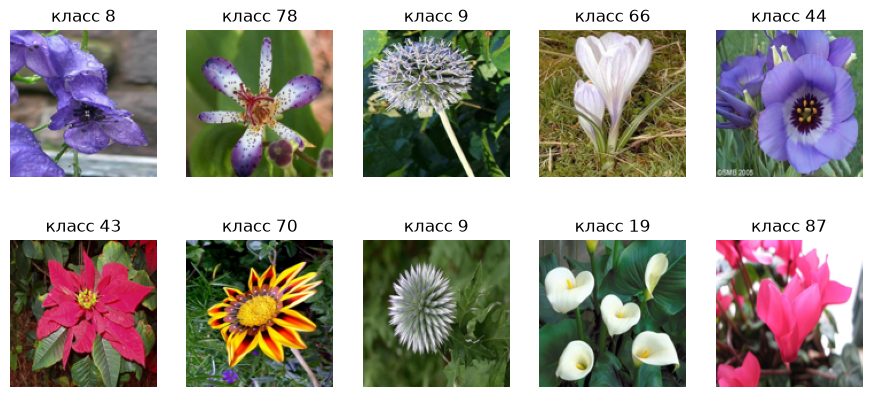

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for ax, image_id in zip(axes.ravel(), example_ids):
    ax.imshow(examples[image_id])
    ax.set_title(f'класс {labels[image_id - 1]}'); ax.axis('off')
display(fig)
plt.close(fig)

In [7]:
means = train_pixels.mean(axis=(0, 1, 2)) / 255
stds = train_pixels.std(axis=(0, 1, 2)) / 255
brightness = train_pixels.mean(axis=(1, 2, 3)) / 255
quantiles = np.quantile(brightness, [0, .01, .5, .99, 1])
print('Среднее RGB [0,1]:', np.round(means, 4))
print('Ст. отклонение:', np.round(stds, 4))
print('Квантили яркости:', np.round(quantiles, 4))

Среднее RGB [0,1]: [0.433  0.3819 0.2964]
Ст. отклонение: [0.2879 0.2388 0.2667]
Квантили яркости: [0.06   0.1385 0.3711 0.6217 0.8531]


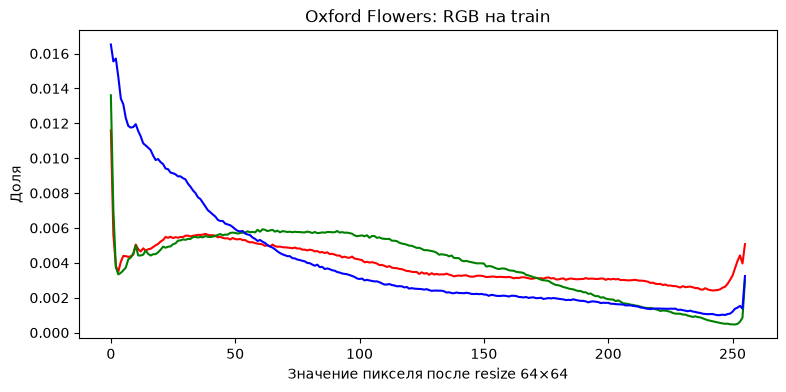

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
for channel, color in enumerate('rgb'):
    hist = np.bincount(train_pixels[:, :, :, channel].ravel(), minlength=256)
    ax.plot(np.arange(256), hist / hist.sum(), color=color, label='RGB'[channel])
ax.set(xlabel='Значение пикселя после resize 64×64', ylabel='Доля', title='Oxford Flowers: RGB на train')
display(fig)
plt.close(fig)

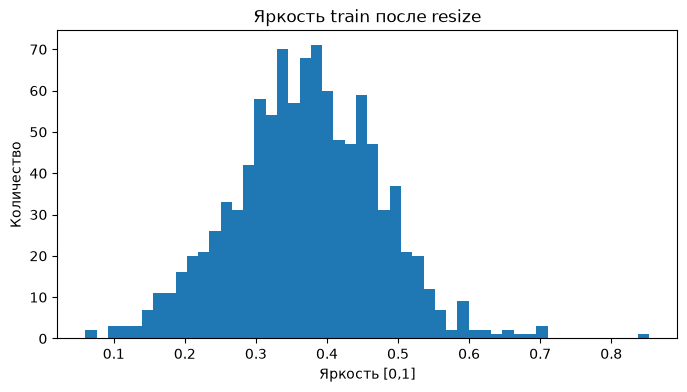

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(brightness, bins=50)
ax.set(xlabel='Яркость [0,1]', ylabel='Количество', title='Яркость train после resize')
display(fig)
plt.close(fig)

## 3.5. Итоговая сводка
Точных дубликатов здесь отдельно не ищем: сравнение цветочных фото требует также проверки похожих кадров, а не только идентичных JPEG.

In [10]:
summary = {
    'dataset': 'Oxford Flowers 102',
    'source': 'https://www.robots.ox.ac.uk/~vgg/data/flowers/102/',
    'image_count': len(widths), 'classes': 102,
    'native_width_min_median_max': [int(min(widths)), float(np.median(widths)), int(max(widths))],
    'native_height_min_median_max': [int(min(heights)), float(np.median(heights)), int(max(heights))],
    'analysis_resize': [64, 64], 'shape': [64, 64, 3],
    'counts_by_class': counts,
    'train_channel_mean_0_1': means.tolist(),
    'train_channel_std_0_1': stds.tolist(),
    'train_brightness_quantiles_0_1': quantiles.tolist(),
    'note': '64×64 — только для EDA; исходные размеры разнородны. Официальный split сохранён.',
}
display(summary)

{'dataset': 'Oxford Flowers 102',
 'source': 'https://www.robots.ox.ac.uk/~vgg/data/flowers/102/',
 'image_count': 8189,
 'classes': 102,
 'native_width_min_median_max': [500, 667.0, 1024],
 'native_height_min_median_max': [500, 500.0, 1168],
 'analysis_resize': [64, 64],
 'shape': [64, 64, 3],
 'counts_by_class': {'train': [10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   10,
   1

### Вывод
В Oxford Flowers 102 снимки цветные, но всего 102 класса и небольшая official train-часть; исходные разрешения разные. Нужно учитывать стоимость выбранного разрешения и объём данных. Количественное сопоставление — в тетради 04, которая сама читает исходные метки.